In [1]:
# 1. Import libraries and configure the environment

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from time import time
import json

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    average_precision_score,
    roc_auc_score
)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)

RANDOM_STATE = 42

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent

DATA_DIR = PROJECT_ROOT / "data" / "splits"
TRAIN_PATH = DATA_DIR / "train.csv"
VALIDATION_PATH = DATA_DIR / "validation.csv"
TEST_PATH = DATA_DIR / "test.csv"

print("Environment configured.")
print("Project root:", PROJECT_ROOT)
print("Random state:", RANDOM_STATE)

Environment configured.
Project root: d:\Programs and Codes\financial-scam-analysis
Random state: 42


In [3]:
# 2. Load dataset partitions

train_df = pd.read_csv(TRAIN_PATH, low_memory=False)
validation_df = pd.read_csv(VALIDATION_PATH, low_memory=False)
test_df = pd.read_csv(TEST_PATH, low_memory=False)

print("Training:", train_df.shape)
print("Validation:", validation_df.shape)
print("Test:", test_df.shape)

print("\nTraining label distribution:")
display(train_df["label"].value_counts().sort_index())

print("\nValidation label distribution:")
display(validation_df["label"].value_counts().sort_index())

print("\nTest label distribution:")
display(test_df["label"].value_counts().sort_index())

Training: (60957, 32)
Validation: (7618, 32)
Test: (7618, 32)

Training label distribution:


label
0    49866
1    11091
Name: count, dtype: int64


Validation label distribution:


label
0    6233
1    1385
Name: count, dtype: int64


Test label distribution:


label
0    6233
1    1385
Name: count, dtype: int64

In [4]:
# 3. Define input features and target labels

TEXT_COLUMN = "normalized_text"
TARGET_COLUMN = "label"

X_train_text = train_df[TEXT_COLUMN].fillna("")
X_val_text = validation_df[TEXT_COLUMN].fillna("")
X_test_text = test_df[TEXT_COLUMN].fillna("")

y_train = train_df[TARGET_COLUMN]
y_val = validation_df[TARGET_COLUMN]
y_test = test_df[TARGET_COLUMN]

print("Training samples:", len(X_train_text))
print("Validation samples:", len(X_val_text))
print("Test samples:", len(X_test_text))

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).sort_index().mul(100).round(2))

print("\nMissing text values:")
print({
    "train": train_df[TEXT_COLUMN].isna().sum(),
    "validation": validation_df[TEXT_COLUMN].isna().sum(),
    "test": test_df[TEXT_COLUMN].isna().sum()
})

Training samples: 60957
Validation samples: 7618
Test samples: 7618

Training target distribution:
label
0    81.81
1    18.19
Name: proportion, dtype: float64

Missing text values:
{'train': np.int64(0), 'validation': np.int64(0), 'test': np.int64(0)}


In [5]:
# 4. Fit word-level TF-IDF

tfidf_vectorizer = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 1),
    min_df=1,
    max_df=1.0,
    dtype=np.float32
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_text)

X_val_tfidf = tfidf_vectorizer.transform(X_val_text)
X_test_tfidf = tfidf_vectorizer.transform(X_test_text)

print("Training matrix:", X_train_tfidf.shape)
print("Validation matrix:", X_val_tfidf.shape)
print("Test matrix:", X_test_tfidf.shape)

print("\nVocabulary size:", len(tfidf_vectorizer.vocabulary_))
print("Training non-zero elements:", X_train_tfidf.nnz)
print("Training matrix data type:", X_train_tfidf.dtype)

Training matrix: (60957, 115436)
Validation matrix: (7618, 115436)
Test matrix: (7618, 115436)

Vocabulary size: 115436
Training non-zero elements: 5052694
Training matrix data type: float32


In [6]:
# 5. Define model evaluation function

def evaluate_model(model, X, y_true, model_name):
    start_time = time()

    y_pred = model.predict(X)

    prediction_time = time() - start_time

    results = {
        "model": model_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "prediction_time_seconds": prediction_time
    }

    return results

In [7]:
# 6. Train Logistic Regression

logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=RANDOM_STATE,
    solver="liblinear"
)

start_time = time()

logistic_model.fit(X_train_tfidf, y_train)

training_time = time() - start_time

print("Logistic Regression training completed.")
print(f"Training time: {training_time:.2f} seconds")
print("Iterations:", logistic_model.n_iter_)

Logistic Regression training completed.
Training time: 1.60 seconds
Iterations: [8]


In [8]:
# 7. Evaluate Logistic Regression on validation data

logistic_results = evaluate_model(
    logistic_model,
    X_val_tfidf,
    y_val,
    "Logistic Regression"
)

display(pd.DataFrame([logistic_results]).round(4))

print("\nDetailed classification report:")
print(
    classification_report(
        y_val,
        logistic_model.predict(X_val_tfidf),
        target_names=["Legitimate", "Financial Scam"],
        digits=4
    )
)

,model,accuracy,precision,recall,f1,prediction_time_seconds
0,Logistic Regression,0.9941,0.9725,0.9957,0.9839,0.0112



Detailed classification report:
                precision    recall  f1-score   support

    Legitimate     0.9990    0.9937    0.9964      6233
Financial Scam     0.9725    0.9957    0.9839      1385

      accuracy                         0.9941      7618
     macro avg     0.9858    0.9947    0.9902      7618
  weighted avg     0.9942    0.9941    0.9941      7618



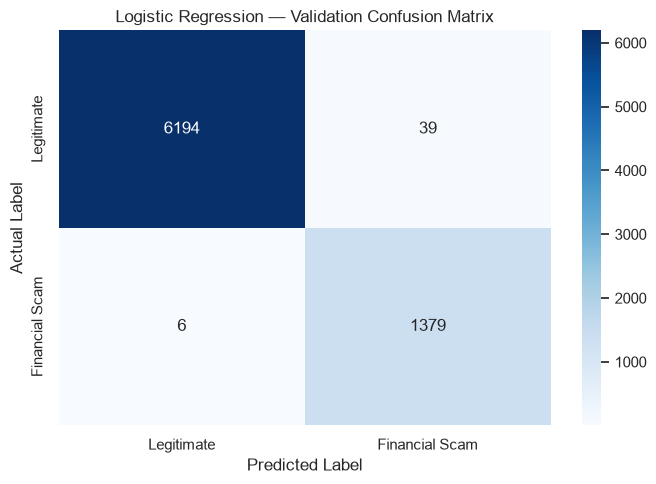

Confusion matrix:
[[6194   39]
 [   6 1379]]


In [9]:
# 8. Generate Logistic Regression confusion matrix

logistic_val_predictions = logistic_model.predict(X_val_tfidf)

cm = confusion_matrix(
    y_val,
    logistic_val_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Financial Scam"],
    yticklabels=["Legitimate", "Financial Scam"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Logistic Regression — Validation Confusion Matrix")

plt.tight_layout()
plt.show()

print("Confusion matrix:")
print(cm)

In [10]:
# 9. Inspect Logistic Regression misclassifications

validation_analysis = validation_df.copy()

validation_analysis["predicted_label"] = logistic_val_predictions

validation_analysis["prediction_type"] = np.select(
    [
        (validation_analysis["label"] == 0) &
        (validation_analysis["predicted_label"] == 1),

        (validation_analysis["label"] == 1) &
        (validation_analysis["predicted_label"] == 0)
    ],
    [
        "False Positive",
        "False Negative"
    ],
    default="Correct"
)

misclassified = validation_analysis[
    validation_analysis["prediction_type"] != "Correct"
].copy()

print("Misclassified records:", len(misclassified))

print("\nMisclassification breakdown:")
display(misclassified["prediction_type"].value_counts())

print("\nFalse positives:")
display(
    misclassified[
        misclassified["prediction_type"] == "False Positive"
    ][["record_id", "source", "channel", "normalized_text"]]
    .head(10)
)

print("\nFalse negatives:")
display(
    misclassified[
        misclassified["prediction_type"] == "False Negative"
    ][["record_id", "source", "channel", "normalized_text"]]
)

Misclassified records: 45

Misclassification breakdown:


prediction_type
False Positive    39
False Negative     6
Name: count, dtype: int64


False positives:


,record_id,source,channel,normalized_text
1385,LEG-FIN-00009,Financial scams detection dataset (Mendeley Data V2),sms,"Your OTP is 8741, do not share it with anyone."
1386,LEG-FIN-00019,Financial scams detection dataset (Mendeley Data V2),sms,"Your BDT 10,000 wallet transfer was successful. Thank you for using our service."
1388,LEG-FIN-00040,Financial scams detection dataset (Mendeley Data V2),sms,Payment of BDT 5000 received. Thank you for your timely payment.
1390,LEG-FIN-00060,Financial scams detection dataset (Mendeley Data V2),sms,Your parcel #XZ1234 is ready for pickup at the post office.
1392,LEG-FIN-00080,Financial scams detection dataset (Mendeley Data V2),sms,Your package #ZX12345 is out for delivery. Track it using our app.
1397,LEG-FIN-00130,Financial scams detection dataset (Mendeley Data V2),sms,Salary allowance of $120 added separately. Check your payroll slip
1400,LEG-FIN-00160,Financial scams detection dataset (Mendeley Data V2),sms,"Team meeting is rescheduled to 3 PM, please confirm your availability."
1401,LEG-FIN-00170,Financial scams detection dataset (Mendeley Data V2),sms,Friend request from Rafi Ahmed. Accept to connect.
1402,LEG-FIN-00180,UCI SMS Spam Collection,sms,Your account has been refilled successfully by INR &lt;DECIMAL&gt; . Your KeralaCircle prepaid a...
1405,LEG-FIN-00210,UCI SMS Spam Collection,sms,"sir, you will receive the account no another 1hr time. Sorry for the delay."



False negatives:


,record_id,source,channel,normalized_text
332,FIN-03320,smishtank.csv,sms,"Votre solde CPF est arriv� a �ch�ance. Veuillez remplir le formulaire ci-dessous sous 24h, pour ..."
360,FIN-03583,smishtank.csv,sms,This is a Flex Alert! The power is ours to help stop an outage now. Conserve energy by delaying ...
730,FIN-07277,Smishing Dataset IMC25 (public user reports),sms,Sorry but Internet Banking isn't available [DATE_TIME]. You won't be able to log in from [DATE_T...
1006,FIN-10001,Smishing Dataset IMC25 (public user reports),sms,HDFCUPI sdU%2FdroABXI7TC4 hD8OMZITexRTP2Fao VltQoNoe7JcVPillhm7 Nqu8ofCHpOy6H
1152,FIN-11451,Smishing Dataset IMC25 (public user reports),sms,"Fwd: PENSION HEADQUARTERS (PTAD) GARKI ABUJA. CALL: [PHONE_NUMBER], HAJIYA BINTA USMAN, REMITTAN..."
1274,FIN-12707,Smishing Dataset IMC25 (public user reports),sms,"⚡ IF YOUR DON'T KNOW ABOUT CRYPTO AND HOW TO USE IT, PLEASE IGNORE THIS MESSAGE"


In [11]:
# 10. Analyze misclassifications by source

source_error_report = (
    misclassified
    .groupby(["source", "prediction_type"])
    .size()
    .unstack(fill_value=0)
)

source_error_report["total_errors"] = source_error_report.sum(axis=1)

display(
    source_error_report.sort_values(
        "total_errors",
        ascending=False
    )
)

prediction_type,False Negative,False Positive,total_errors
source,,,
UCI SMS Spam Collection,0,18,18
MeAJOR (trec5),0,12,12
Financial scams detection dataset (Mendeley Data V2),0,8,8
Smishing Dataset IMC25 (public user reports),4,0,4
smishtank.csv,2,0,2
MeAJOR (trec7),0,1,1


In [12]:
# 11. Calculate source-level validation error rates

source_performance = (
    validation_analysis
    .groupby(["source", "label"])
    .agg(
        total_records=("record_id", "count"),
        errors=("prediction_type", lambda x: (x != "Correct").sum())
    )
    .reset_index()
)

source_performance["error_rate"] = (
    source_performance["errors"] /
    source_performance["total_records"] * 100
)

source_performance["class"] = source_performance["label"].map({
    0: "Legitimate",
    1: "Financial Scam"
})

display(
    source_performance[
        ["source", "class", "total_records", "errors", "error_rate"]
    ].sort_values(["class", "error_rate"], ascending=[True, False])
    .round(2)
)

,source,class,total_records,errors,error_rate
8,smishtank.csv,Financial Scam,46,2,4.35
6,Smishing Dataset IMC25 (public user reports),Financial Scam,963,4,0.42
4,Nigerian_Fraud.csv,Financial Scam,326,0,0.00
5,Phishing and Legitimate Emails Dataset (Kaggle),Financial Scam,50,0,0.00
0,Financial scams detection dataset (Mendeley Data V2),Legitimate,17,8,47.06
7,UCI SMS Spam Collection,Legitimate,450,18,4.00
1,MeAJOR (trec5),Legitimate,2722,12,0.44
3,MeAJOR (trec7),Legitimate,1933,1,0.05
2,MeAJOR (trec6),Legitimate,1111,0,0.00


In [13]:
# 12. Inspect all Mendeley validation records

mendeley_validation = validation_analysis[
    validation_analysis["source"] ==
    "Financial scams detection dataset (Mendeley Data V2)"
].copy()

display(
    mendeley_validation[
        [
            "record_id",
            "label",
            "predicted_label",
            "prediction_type",
            "channel",
            "normalized_text"
        ]
    ].sort_values("prediction_type")
)

print("\nMendeley prediction breakdown:")
display(
    pd.crosstab(
        mendeley_validation["label"],
        mendeley_validation["predicted_label"],
        rownames=["Actual"],
        colnames=["Predicted"]
    )
)

,record_id,label,predicted_label,prediction_type,channel,normalized_text
1393,LEG-FIN-00090,0,0,Correct,sms,Can you send me your notes for today's class?
1399,LEG-FIN-00150,0,0,Correct,sms,"Paid the school fees of 12,500 BDT today. Please acknowledge"
1387,LEG-FIN-00029,0,0,Correct,sms,Avoid fake schemes promising overnight wealth. Stay cautious.
1398,LEG-FIN-00140,0,0,Correct,sms,"Mom sent 1,200 BDT through Rocket. Check if it reflects in your balance"
1389,LEG-FIN-00050,0,0,Correct,sms,Thank you for your recent payment of BDT 3000.
1391,LEG-FIN-00070,0,0,Correct,sms,Your mobile recharge of BDT 300 was successful.
1396,LEG-FIN-00120,0,0,Correct,sms,"Payment confirmation: Received 4,200 BDT for the event booking. Thanks for the prompt payment"
1395,LEG-FIN-00110,0,0,Correct,sms,"Nagad e 500 taka pathaisi, mama. Dekho paiso naki"
1394,LEG-FIN-00100,0,0,Correct,sms,"Your taxi will arrive in 7 minutes. Driver: Saiful, Car: Blue Toyota."
1397,LEG-FIN-00130,0,1,False Positive,sms,Salary allowance of $120 added separately. Check your payroll slip



Mendeley prediction breakdown:


Predicted,0,1
Actual,,
0,9,8


In [14]:
# 13. Evaluate Logistic Regression by communication channel

channel_results = []

for channel in sorted(validation_df["channel"].dropna().unique()):

    channel_mask = validation_df["channel"] == channel

    y_true_channel = y_val[channel_mask]
    y_pred_channel = logistic_val_predictions[channel_mask]

    channel_results.append({
        "channel": channel,
        "records": len(y_true_channel),
        "accuracy": accuracy_score(y_true_channel, y_pred_channel),
        "scam_precision": precision_score(
            y_true_channel, y_pred_channel, zero_division=0
        ),
        "scam_recall": recall_score(
            y_true_channel, y_pred_channel, zero_division=0
        ),
        "scam_f1": f1_score(
            y_true_channel, y_pred_channel, zero_division=0
        )
    })

channel_performance = pd.DataFrame(channel_results)

display(
    channel_performance.round(4)
)

,channel,records,accuracy,scam_precision,scam_recall,scam_f1
0,email,6142,0.9979,0.9666,1.0000,0.9830
1,sms,1476,0.9783,0.9747,0.9941,0.9843


In [16]:
# 14. Audit semantic placeholder distribution

placeholder_pattern = r"\[[A-Z][A-Z0-9_]*\]"

train_df["placeholder_count"] = (
    train_df["normalized_text"]
    .str.count(placeholder_pattern)
)

train_df["contains_placeholder"] = (
    train_df["placeholder_count"] > 0
)

placeholder_distribution = (
    train_df.groupby("label")
    .agg(
        total_records=("record_id", "count"),
        records_with_placeholders=("contains_placeholder", "sum"),
        mean_placeholder_count=("placeholder_count", "mean")
    )
)

placeholder_distribution["placeholder_prevalence"] = (
    placeholder_distribution["records_with_placeholders"] /
    placeholder_distribution["total_records"] * 100
)

display(placeholder_distribution.round(3))

,total_records,records_with_placeholders,mean_placeholder_count,placeholder_prevalence
label,,,,
0,49866,44737,14.913,89.714
1,11091,8782,1.620,79.181


In [17]:
# 15. Create placeholder-free text variant

import re

def remove_placeholders(text):
    return re.sub(
        r"\[[A-Z][A-Z0-9_]*\]",
        "",
        str(text)
    )

train_df["text_no_placeholders"] = (
    train_df["normalized_text"]
    .fillna("")
    .apply(remove_placeholders)
)

validation_df["text_no_placeholders"] = (
    validation_df["normalized_text"]
    .fillna("")
    .apply(remove_placeholders)
)

print("Training records:", len(train_df))
print("Validation records:", len(validation_df))

print(
    "Training records changed:",
    (
        train_df["normalized_text"] !=
        train_df["text_no_placeholders"]
    ).sum()
)

print("\nBefore:")
print(train_df["normalized_text"].iloc[0][:500])

print("\nAfter:")
print(train_df["text_no_placeholders"].iloc[0][:500])

Training records: 60957
Validation records: 7618
Training records changed: 53519

Before:
URGENT BUSINESS ASSISTANCE AND PARTNERSHIP FROM:MR. JAMES NGOLA.
CONFIDENTIAL TEL: [PHONE_NUMBER].
E-MAIL: ([EMAIL_ADDRESS]).

URGENT BUSINESS ASSISTANCE AND PARTNERSHIP.


DEAR FRIEND,

I AM ( DR.) JAMES NGOLA, THE PERSONAL ASSISTANCE TO THE LATE CONGOLESE (PRESIDENT LAURENT KABILA) WHO WAS ASSASSINATED BY HIS BODY GUARD ON 16TH JAN. 2001.


THE INCIDENT OCCURRED IN OUR PRESENCE WHILE WE WERE HOLDING MEETING WITH HIS EXCELLENCY OVER THE FINANCIAL RETURNS FROM THE DIAMOND SALES IN THE AREAS CONT

After:
URGENT BUSINESS ASSISTANCE AND PARTNERSHIP FROM:MR. JAMES NGOLA.
CONFIDENTIAL TEL: .
E-MAIL: ().

URGENT BUSINESS ASSISTANCE AND PARTNERSHIP.


DEAR FRIEND,

I AM ( DR.) JAMES NGOLA, THE PERSONAL ASSISTANCE TO THE LATE CONGOLESE (PRESIDENT LAURENT KABILA) WHO WAS ASSASSINATED BY HIS BODY GUARD ON 16TH JAN. 2001.


THE INCIDENT OCCURRED IN OUR PRESENCE WHILE WE WERE HOLDING MEETING WITH HIS EXCELLEN

In [19]:
# 16. Clean text after placeholder removal

def remove_placeholders_cleanly(text):
    text = str(text)

    # Remove semantic placeholders
    text = re.sub(r"\[[A-Z][A-Z0-9_]*\]", "", text)

    # Remove empty parentheses
    text = re.sub(r"\(\s*\)", "", text)

    # Remove punctuation left directly after an empty field
    text = re.sub(r"(?<=:)\s*[.,;]", "", text)

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text)

    # Remove spaces before punctuation
    text = re.sub(r"\s+([.,!?;:])", r"\1", text)

    return text.strip()


train_df["text_no_placeholders"] = (
    train_df["normalized_text"]
    .fillna("")
    .apply(remove_placeholders_cleanly)
)

validation_df["text_no_placeholders"] = (
    validation_df["normalized_text"]
    .fillna("")
    .apply(remove_placeholders_cleanly)
)

print("Before:")
print(train_df["normalized_text"].iloc[0][:250])

print("\nAfter:")
print(train_df["text_no_placeholders"].iloc[0][:250])

Before:
URGENT BUSINESS ASSISTANCE AND PARTNERSHIP FROM:MR. JAMES NGOLA.
CONFIDENTIAL TEL: [PHONE_NUMBER].
E-MAIL: ([EMAIL_ADDRESS]).

URGENT BUSINESS ASSISTANCE AND PARTNERSHIP.


DEAR FRIEND,

I AM ( DR.) JAMES NGOLA, THE PERSONAL ASSISTANCE TO THE LATE CO

After:
URGENT BUSINESS ASSISTANCE AND PARTNERSHIP FROM:MR. JAMES NGOLA. CONFIDENTIAL TEL: E-MAIL: URGENT BUSINESS ASSISTANCE AND PARTNERSHIP. DEAR FRIEND, I AM ( DR.) JAMES NGOLA, THE PERSONAL ASSISTANCE TO THE LATE CONGOLESE (PRESIDENT LAURENT KABILA) WHO 


In [20]:
# 17. Build TF-IDF features without placeholders

tfidf_no_placeholder_vectorizer = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 1),
    min_df=1,
    max_df=1.0,
    dtype=np.float32
)

X_train_tfidf_no_placeholders = (
    tfidf_no_placeholder_vectorizer.fit_transform(
        train_df["text_no_placeholders"]
    )
)

X_val_tfidf_no_placeholders = (
    tfidf_no_placeholder_vectorizer.transform(
        validation_df["text_no_placeholders"]
    )
)

print("Training matrix:", X_train_tfidf_no_placeholders.shape)
print("Validation matrix:", X_val_tfidf_no_placeholders.shape)
print("Vocabulary size:", len(tfidf_no_placeholder_vectorizer.vocabulary_))
print("Training non-zero values:", X_train_tfidf_no_placeholders.nnz)

Training matrix: (60957, 116668)
Validation matrix: (7618, 116668)
Vocabulary size: 116668
Training non-zero values: 4871231


In [21]:
# 18. Train Logistic Regression without placeholders

logistic_no_placeholder_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=RANDOM_STATE,
    solver="liblinear"
)

start_time = time()

logistic_no_placeholder_model.fit(
    X_train_tfidf_no_placeholders,
    y_train
)

training_time_no_placeholders = time() - start_time

print(f"Training time: {training_time_no_placeholders:.2f} seconds")
print("Iterations:", logistic_no_placeholder_model.n_iter_[0])

Training time: 1.49 seconds
Iterations: 8


In [22]:
# 19. Evaluate placeholder-free model

y_val_pred_no_placeholders = logistic_no_placeholder_model.predict(
    X_val_tfidf_no_placeholders
)

print(classification_report(
    y_val,
    y_val_pred_no_placeholders,
    target_names=["Legitimate", "Financial Scam"],
    digits=4
))

cm_no_placeholders = confusion_matrix(
    y_val,
    y_val_pred_no_placeholders
)

print("Confusion Matrix:")
print(cm_no_placeholders)

                precision    recall  f1-score   support

    Legitimate     0.9961    0.9925    0.9943      6233
Financial Scam     0.9666    0.9827    0.9746      1385

      accuracy                         0.9907      7618
     macro avg     0.9814    0.9876    0.9844      7618
  weighted avg     0.9908    0.9907    0.9907      7618

Confusion Matrix:
[[6186   47]
 [  24 1361]]


In [23]:
# 20. Replace all semantic placeholders with a generic token

def replace_placeholders_with_generic(text):
    text = str(text)

    text = re.sub(r"\[[A-Z][A-Z0-9_]*\]", " [REDACTED] ", text)
    text = re.sub(r"\(\s*\)", " ", text)
    text = re.sub(r"\s+", " ", text)

    return text.strip()


train_df["text_generic_redaction"] = (
    train_df["normalized_text"]
    .fillna("")
    .apply(replace_placeholders_with_generic)
)

validation_df["text_generic_redaction"] = (
    validation_df["normalized_text"]
    .fillna("")
    .apply(replace_placeholders_with_generic)
)

print("Before:")
print(train_df["normalized_text"].iloc[0][:250])

print("\nAfter:")
print(train_df["text_generic_redaction"].iloc[0][:250])

Before:
URGENT BUSINESS ASSISTANCE AND PARTNERSHIP FROM:MR. JAMES NGOLA.
CONFIDENTIAL TEL: [PHONE_NUMBER].
E-MAIL: ([EMAIL_ADDRESS]).

URGENT BUSINESS ASSISTANCE AND PARTNERSHIP.


DEAR FRIEND,

I AM ( DR.) JAMES NGOLA, THE PERSONAL ASSISTANCE TO THE LATE CO

After:
URGENT BUSINESS ASSISTANCE AND PARTNERSHIP FROM:MR. JAMES NGOLA. CONFIDENTIAL TEL: [REDACTED] . E-MAIL: ( [REDACTED] ). URGENT BUSINESS ASSISTANCE AND PARTNERSHIP. DEAR FRIEND, I AM ( DR.) JAMES NGOLA, THE PERSONAL ASSISTANCE TO THE LATE CONGOLESE (P


In [24]:
def replace_placeholders_with_generic(text):
    text = str(text)

    text = re.sub(r"\[[A-Z][A-Z0-9_]*\]", "[REDACTED]", text)

    # Clean spaces inside parentheses
    text = re.sub(r"\(\s*\[REDACTED\]\s*\)", "[REDACTED]", text)

    # Normalize whitespace and punctuation
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"\s+([.,!?;:])", r"\1", text)

    return text.strip()


train_df["text_generic_redaction"] = (
    train_df["normalized_text"].fillna("").apply(replace_placeholders_with_generic)
)

validation_df["text_generic_redaction"] = (
    validation_df["normalized_text"].fillna("").apply(replace_placeholders_with_generic)
)

print(train_df["text_generic_redaction"].iloc[0][:250])

URGENT BUSINESS ASSISTANCE AND PARTNERSHIP FROM:MR. JAMES NGOLA. CONFIDENTIAL TEL: [REDACTED]. E-MAIL: [REDACTED]. URGENT BUSINESS ASSISTANCE AND PARTNERSHIP. DEAR FRIEND, I AM ( DR.) JAMES NGOLA, THE PERSONAL ASSISTANCE TO THE LATE CONGOLESE (PRESID


In [25]:
# 21. Build TF-IDF features with generic redaction

tfidf_generic_vectorizer = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 1),
    min_df=1,
    max_df=1.0,
    dtype=np.float32
)

X_train_tfidf_generic = tfidf_generic_vectorizer.fit_transform(
    train_df["text_generic_redaction"]
)

X_val_tfidf_generic = tfidf_generic_vectorizer.transform(
    validation_df["text_generic_redaction"]
)

print("Training matrix:", X_train_tfidf_generic.shape)
print("Validation matrix:", X_val_tfidf_generic.shape)
print("Vocabulary size:", len(tfidf_generic_vectorizer.vocabulary_))
print("Training non-zero values:", X_train_tfidf_generic.nnz)

Training matrix: (60957, 115378)
Validation matrix: (7618, 115378)
Vocabulary size: 115378
Training non-zero values: 4925206


In [26]:
# 22. Train Logistic Regression with generic redaction

logistic_generic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=RANDOM_STATE,
    solver="liblinear"
)

start_time = time()

logistic_generic_model.fit(
    X_train_tfidf_generic,
    y_train
)

training_time_generic = time() - start_time

print(f"Training time: {training_time_generic:.2f} seconds")
print("Iterations:", logistic_generic_model.n_iter_[0])

Training time: 1.66 seconds
Iterations: 8


In [27]:
# 23. Evaluate generic-redaction model

y_val_pred_generic = logistic_generic_model.predict(
    X_val_tfidf_generic
)

print(classification_report(
    y_val,
    y_val_pred_generic,
    target_names=["Legitimate", "Financial Scam"],
    digits=4
))

cm_generic = confusion_matrix(
    y_val,
    y_val_pred_generic
)

print("Confusion Matrix:")
print(cm_generic)

                precision    recall  f1-score   support

    Legitimate     0.9958    0.9917    0.9937      6233
Financial Scam     0.9631    0.9812    0.9721      1385

      accuracy                         0.9898      7618
     macro avg     0.9795    0.9864    0.9829      7618
  weighted avg     0.9899    0.9898    0.9898      7618

Confusion Matrix:
[[6181   52]
 [  26 1359]]


In [28]:
# 24. Compare all three placeholder experiments

predictions = {
    "Original": logistic_model.predict(X_val_tfidf),
    "No Placeholders": y_val_pred_no_placeholders,
    "Generic Redaction": y_val_pred_generic
}

ablation_results = []

for variant, predictions_variant in predictions.items():
    ablation_results.append({
        "Variant": variant,
        "Accuracy": accuracy_score(y_val, predictions_variant),
        "Scam Precision": precision_score(y_val, predictions_variant),
        "Scam Recall": recall_score(y_val, predictions_variant),
        "Scam F1": f1_score(y_val, predictions_variant),
        "False Positives": confusion_matrix(
            y_val, predictions_variant
        )[0, 1],
        "False Negatives": confusion_matrix(
            y_val, predictions_variant
        )[1, 0]
    })

ablation_comparison = pd.DataFrame(ablation_results)

display(
    ablation_comparison.style.format({
        "Accuracy": "{:.4%}",
        "Scam Precision": "{:.4%}",
        "Scam Recall": "{:.4%}",
        "Scam F1": "{:.4%}"
    })
)

,Variant,Accuracy,Scam Precision,Scam Recall,Scam F1,False Positives,False Negatives
0,Original,99.4093%,97.2496%,99.5668%,98.3946%,39,6
1,No Placeholders,99.0680%,96.6619%,98.2671%,97.4579%,47,24
2,Generic Redaction,98.9761%,96.3147%,98.1227%,97.2103%,52,26


In [29]:
# 25. Evaluate original model by dataset source

source_analysis = validation_df.copy()

source_analysis["predicted_label"] = logistic_model.predict(
    X_val_tfidf
)

source_results = []

for source, group in source_analysis.groupby("source"):
    source_results.append({
        "Source": source,
        "Records": len(group),
        "Accuracy": accuracy_score(
            group["label"], group["predicted_label"]
        ),
        "Scam Recall": (
            recall_score(
                group["label"], group["predicted_label"],
                zero_division=0
            )
            if group["label"].nunique() > 1 or group["label"].iloc[0] == 1
            else np.nan
        ),
        "Errors": (group["label"] != group["predicted_label"]).sum()
    })

source_performance = pd.DataFrame(source_results)

display(
    source_performance.sort_values(
        "Records", ascending=False
    ).style.format({
        "Accuracy": "{:.4%}",
        "Scam Recall": "{:.4%}"
    })
)

,Source,Records,Accuracy,Scam Recall,Errors
1,MeAJOR (trec5),2722,99.5591%,nan%,12
3,MeAJOR (trec7),1933,99.9483%,nan%,1
2,MeAJOR (trec6),1111,100.0000%,nan%,0
6,Smishing Dataset IMC25 (public user reports),963,99.5846%,99.5846%,4
7,UCI SMS Spam Collection,450,96.0000%,nan%,18
4,Nigerian_Fraud.csv,326,100.0000%,100.0000%,0
5,Phishing and Legitimate Emails Dataset (Kaggle),50,100.0000%,100.0000%,0
8,smishtank.csv,46,95.6522%,95.6522%,2
0,Financial scams detection dataset (Mendeley Data V2),17,52.9412%,nan%,8


In [30]:
# 26. Inspect Mendeley prediction confidence

mendeley_errors = source_analysis[
    (source_analysis["source"] == "Financial scams detection dataset (Mendeley Data V2)") &
    (source_analysis["label"] != source_analysis["predicted_label"])
].copy()

mendeley_errors["scam_probability"] = logistic_model.predict_proba(
    X_val_tfidf
)[:, 1][mendeley_errors.index]

display(
    mendeley_errors[
        ["record_id", "label", "predicted_label",
         "scam_probability", "normalized_text"]
    ]
)

,record_id,label,predicted_label,scam_probability,normalized_text
1385,LEG-FIN-00009,0,1,0.796731,"Your OTP is 8741, do not share it with anyone."
1386,LEG-FIN-00019,0,1,0.617932,"Your BDT 10,000 wallet transfer was successful. Thank you for using our service."
1388,LEG-FIN-00040,0,1,0.741844,Payment of BDT 5000 received. Thank you for your timely payment.
1390,LEG-FIN-00060,0,1,0.514696,Your parcel #XZ1234 is ready for pickup at the post office.
1392,LEG-FIN-00080,0,1,0.821843,Your package #ZX12345 is out for delivery. Track it using our app.
1397,LEG-FIN-00130,0,1,0.696213,Salary allowance of $120 added separately. Check your payroll slip
1400,LEG-FIN-00160,0,1,0.711661,"Team meeting is rescheduled to 3 PM, please confirm your availability."
1401,LEG-FIN-00170,0,1,0.658025,Friend request from Rafi Ahmed. Accept to connect.


In [31]:
# 27. Inspect the strongest learned features

feature_names = np.array(tfidf_vectorizer.get_feature_names_out())
coefficients = logistic_model.coef_[0]

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

top_scam_features = feature_importance.nlargest(
    25, "coefficient"
)

top_legitimate_features = feature_importance.nsmallest(
    25, "coefficient"
)

print("Top scam-associated features:")
display(top_scam_features)

print("Top legitimate-associated features:")
display(top_legitimate_features)

Top scam-associated features:


,feature,coefficient
71256,named_entity,8.624860
114640,your,8.429104
14829,account,8.329803
90709,rs,6.365312
69505,money,6.294679
26428,card,6.069578
78799,payment,5.809980
21419,bank,5.678185
78760,pay,5.066846
34968,dear,4.986993


Top legitimate-associated features:


,feature,coefficient
79655,person_name,-16.185834
76462,organization,-15.991706
83261,product,-5.984299
21944,bdt,-5.684058
101306,system_artifact,-4.706607
41159,email,-4.334269
103225,the,-4.275216
86249,re,-4.270073
45633,file,-3.775116
48250,fw,-3.734249


In [32]:
# 28. Examine selected features across classes

selected_features = [
    "person_name",
    "organization",
    "named_entity",
    "product",
    "bdt",
    "account",
    "money",
    "payment",
    "bank",
    "transfer"
]

feature_distribution = []

for feature in selected_features:
    if feature not in tfidf_vectorizer.vocabulary_:
        continue

    feature_index = tfidf_vectorizer.vocabulary_[feature]

    feature_present = X_train_tfidf[:, feature_index].toarray().ravel() > 0

    for label in [0, 1]:
        mask = y_train.to_numpy() == label

        feature_distribution.append({
            "Feature": feature,
            "Class": "Legitimate" if label == 0 else "Scam",
            "Records": int(mask.sum()),
            "Present": int(feature_present[mask].sum()),
            "Prevalence (%)": (
                feature_present[mask].mean() * 100
            )
        })

feature_distribution_df = pd.DataFrame(feature_distribution)

display(
    feature_distribution_df.pivot(
        index="Feature",
        columns="Class",
        values="Prevalence (%)"
    ).round(3)
)

Class,Legitimate,Scam
Feature,,
account,2.505,44.487
bank,0.652,24.624
bdt,0.122,0.000
money,1.811,19.872
named_entity,0.000,10.414
organization,54.787,1.091
payment,1.332,12.677
person_name,77.730,0.045
product,24.309,0.478


In [33]:
# 29. Examine placeholder features by source

placeholder_features = [
    "person_name",
    "organization",
    "named_entity",
    "product"
]

source_feature_data = train_df.copy()

for feature in placeholder_features:
    feature_index = tfidf_vectorizer.vocabulary_.get(feature)

    if feature_index is not None:
        source_feature_data[feature] = (
            X_train_tfidf[:, feature_index].toarray().ravel() > 0
        )

source_placeholder_summary = (
    source_feature_data
    .groupby(["source", "label"])[placeholder_features]
    .mean()
    .mul(100)
    .round(2)
    .reset_index()
)

display(source_placeholder_summary)

,source,label,person_name,organization,named_entity,product
0,Financial scams detection dataset (Mendeley Data V2),0,0.00,0.00,0.00,0.00
1,MeAJOR (trec5),0,81.41,70.54,0.00,14.17
2,MeAJOR (trec6),0,86.62,49.42,0.00,39.99
3,MeAJOR (trec7),0,86.23,48.83,0.00,35.53
4,Nigerian_Fraud.csv,1,0.00,4.63,0.00,0.80
5,Phishing and Legitimate Emails Dataset (Kaggle),1,0.00,0.00,0.00,0.00
6,Smishing Dataset IMC25 (public user reports),1,0.07,0.00,15.05,0.40
7,UCI SMS Spam Collection,0,0.00,0.00,0.00,0.00
8,smishtank.csv,1,0.00,0.00,0.00,0.25


### Placeholder and Source-Association Investigation

The feature analysis revealed substantial source-associated
placeholder imbalance in the training corpus.

- `person_name` occurred in 77.73% of legitimate records and
  0.045% of scam records.
- `organization` occurred in 54.787% of legitimate records
  and 1.091% of scam records.
- `named_entity` occurred in 0% of legitimate records and
  10.414% of scam records.

Source-level analysis showed that `person_name` and
`organization` placeholders were predominantly associated
with the MeAJOR legitimate email corpus, whereas
`named_entity` was associated with IMC25 scam messages.

The original Logistic Regression model assigned strong
coefficients to these features. Placeholder ablation also
reduced validation performance:

- Original accuracy: 99.4093%
- Placeholder-free accuracy: 99.0680%
- Generic-redaction accuracy: 98.9761%

These findings indicate that the baseline is sensitive to
source-associated annotation conventions. Consequently,
the original validation performance should not be interpreted
as sufficient evidence of robust cross-source scam detection.

The original corpus was retained. Further evaluation should
investigate source generalization and legitimate financial
message coverage.